# 04 — Document Classification & Ad-hoc Prediction

Pipeline stage 4 of 5.

Loads:
- `artifacts/cti_text_classifier.joblib`
- `data/processed/uploaded_docs.pkl`

Classifies every uploaded document and demonstrates ad-hoc snippet prediction.

Saves:
- `artifacts/classified_documents.csv`


In [17]:

# ---------------------------------------------------------------------------
# Bootstrap — paths, imports, global config
# ---------------------------------------------------------------------------
import os
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(r"D:\Projects\done\thesis\ctc_ectd")
SCRIPTS_DIR  = PROJECT_ROOT / "scripts"
UPLOAD_DIR   = PROJECT_ROOT / "uploads"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

for d in (SCRIPTS_DIR, UPLOAD_DIR, ARTIFACT_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

print("PROJECT_ROOT :", PROJECT_ROOT)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("ARTIFACT_DIR :", ARTIFACT_DIR)
print("UPLOAD_DIR   :", UPLOAD_DIR)


PROJECT_ROOT : D:\Projects\done\thesis\ctc_ectd
PROCESSED_DIR: D:\Projects\done\thesis\ctc_ectd\data\processed
ARTIFACT_DIR : D:\Projects\done\thesis\ctc_ectd\artifacts
UPLOAD_DIR   : D:\Projects\done\thesis\ctc_ectd\uploads


In [18]:

import joblib

best_model = joblib.load(ARTIFACT_DIR / "cti_text_classifier.joblib")
print("Model loaded:", type(best_model).__name__)
print("Steps:", list(best_model.named_steps))

uploaded_df = pd.read_pickle(PROCESSED_DIR / "uploaded_docs.pkl")
print("Uploaded docs:", len(uploaded_df))


Model loaded: Pipeline
Steps: ['tfidf', 'clf']
Uploaded docs: 10


## 1. Classify uploaded documents

,file_name,extension,word_count,predicted_category,confidence
6,2025-01_insider_threat_report_07.pdf,.pdf,132,Insider Threat,0.9271
7,2025-03_botnet_report_08.pdf,.pdf,128,Botnet,0.8956
5,2024-11_data_breach_report_06.pdf,.pdf,133,Data Breach,0.8609
2,2024-05_credential_theft_report_03.pdf,.pdf,137,Credential Theft,0.8124
4,2024-09_web_attack_report_05.pdf,.pdf,127,Web Attack,0.8079
0,2024-01_phishing_report_01.pdf,.pdf,140,Phishing,0.6148
1,2024-03_ransomware_report_02.pdf,.pdf,135,Ransomware,0.6082
3,2024-07_ddos_report_04.pdf,.pdf,129,DDoS,0.3923
9,2025-07_credential_theft_report_10.pdf,.pdf,133,Credential Theft,0.3895
8,2025-05_vulnerability_report_09.pdf,.pdf,133,Malware,0.2490


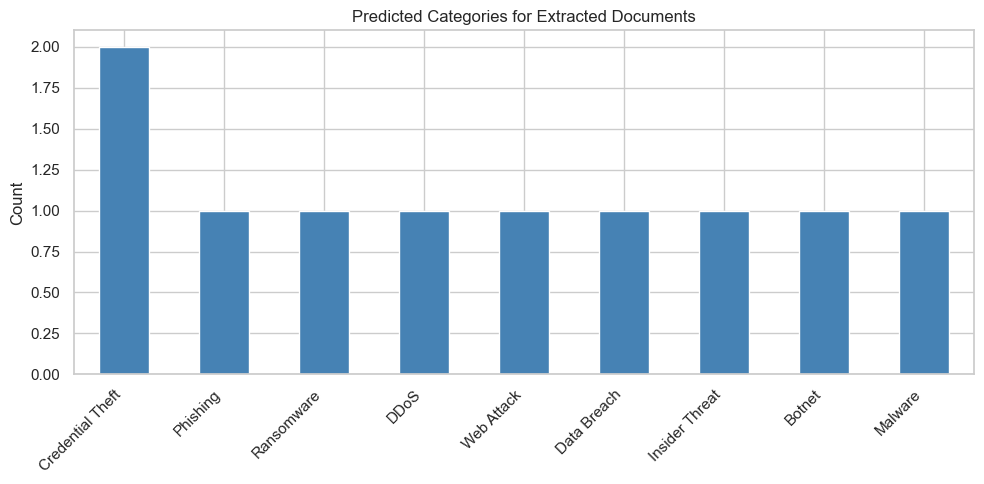

Saved: D:\Projects\done\thesis\ctc_ectd\artifacts\classified_documents.csv


In [19]:

if not uploaded_df.empty and (uploaded_df["text"] != "").any():
    docs = uploaded_df[uploaded_df["text"] != ""].copy()
    docs["predicted_category"] = best_model.predict(docs["text"])

    clf = best_model.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        probs = best_model.predict_proba(docs["text"])
        docs["confidence"] = probs.max(axis=1).round(4)
    elif hasattr(clf, "decision_function"):
        scores = best_model.decision_function(docs["text"])
        docs["confidence"] = np.max(scores, axis=1).round(4)
    else:
        docs["confidence"] = np.nan

    display(docs[["file_name", "extension", "word_count",
                  "predicted_category", "confidence"]]
            .sort_values("confidence", ascending=False))

    plt.figure(figsize=(10, 5))
    docs["predicted_category"].value_counts().plot(kind="bar",
                                                   color="steelblue")
    plt.title("Predicted Categories for Extracted Documents")
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout(); plt.show()

    docs.to_csv(ARTIFACT_DIR / "classified_documents.csv", index=False)
    print("Saved:", ARTIFACT_DIR / "classified_documents.csv")
else:
    print("No extracted documents available to classify.")
    print("Add files to:", UPLOAD_DIR, "and re-run notebook 01.")
    pd.DataFrame(columns=["file_name", "predicted_category", "confidence"]) \
        .to_csv(ARTIFACT_DIR / "classified_documents.csv", index=False)


## 2. Ad-hoc prediction on a new CTI snippet

In [20]:

new_report = """
Multiple organizations report suspicious credential theft activity.
Attackers use phishing emails to obtain account credentials
and attempt unauthorized access to corporate systems.
"""

predicted_category = best_model.predict([new_report])[0]
print("Predicted category:", predicted_category)

clf = best_model.named_steps["clf"]
if hasattr(clf, "predict_proba"):
    proba = best_model.predict_proba([new_report])[0]
    classes = best_model.named_steps["clf"].classes_
    for cls, p in sorted(zip(classes, proba), key=lambda x: -x[1])[:5]:
        print(f"  {cls:<20} {p:.4f}")


Predicted category: Credential Theft
  Credential Theft     0.9907
  Phishing             0.0039
  Data Breach          0.0012
  Insider Threat       0.0010
  DDoS                 0.0006
